# Módulo 4: Aprendizaje Automático (Machine Learning)
## Semana 2 - Clase 5: Taller Comparativo de Clasificadores

En la clase anterior utilizamos **Regresión Logística** para predecir categorías. Sin embargo, en la Inteligencia Artificial existe el teorema del *"No Free Lunch"* (No hay almuerzo gratis), que dicta que **ningún algoritmo es perfecto para todos los problemas**.

Hoy realizaremos un **Taller Comparativo** paso a paso. Usaremos un dataset químico de **Vinos** y enfrentaremos a 4 algoritmos con filosofías radicalmente distintas para ver cómo "piensan" y cómo toman decisiones:

1. **k-Nearest Neighbors (k-NN):** Filosofía basada en Similitud y Distancia (Geometría).
2. **Árboles de Decisión:** Filosofía basada en Reglas Lógicas (If-Then).
3. **Naive Bayes:** Filosofía basada en Probabilidad Teórica.
4. **Random Forest (Bosque Aleatorio):** *(Añadido)* Filosofía basada en la Sabiduría de la Multitud (muchos árboles votando).

> Al final del cuaderno encontrarás la **tabla de calor (heatmap) VS**, el experimento de velocidad/pocos datos y la explicación de por qué **Naive Bayes** es la mejor opción costo-beneficio frente a k-NN y Árbol.

---
## **Paso 1: Extracción y Exploración de Datos**

Utilizaremos el famoso dataset *Wine Quality* incluido en `scikit-learn`. El objetivo es predecir de qué **cultivo (Clase 0, 1 o 2)** proviene un vino basándonos en sus componentes químicos.

### Diccionario de Datos (Traducción al Español)
Dado que las bases de datos originales están en inglés, aquí detallamos el propósito de cada columna para entender la química del vino:
- **Alcohol:** Grado alcohólico del vino.
- **Acido_Malico (Malic Acid):** Un ácido natural del vino que da sabor agrio.
- **Ceniza (Ash):** Cantidad de material inorgánico restante tras la evaporación.
- **Alcalinidad_Ceniza (Alcalinity of Ash):** Medida de qué tan alcalina es la ceniza.
- **Magnesio (Magnesium):** Mineral presente en el vino.
- **Fenoles_Totales (Total Phenols):** Compuestos químicos que afectan el sabor y color.
- **Flavonoides (Flavanoids):** Antioxidantes naturales en la uva.
- **Fenoles_No_Flavonoides:** Otro tipo de compuesto aromático.
- **Proantocianidinas:** Taninos que dan estructura y astringencia al vino.
- **Intensidad_Color:** Qué tan oscuro es el vino.
- **Matiz (Hue):** Tonalidad del color del vino.
- **OD280_OD315:** Medida de dilución del vino (prueba de pureza de proteínas).
- **Prolina (Proline):** Un aminoácido principal presente en la uva.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ocultar advertencias para una clase más limpia
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine

datos_vino = load_wine()
X = pd.DataFrame(datos_vino.data, columns=datos_vino.feature_names)
y = pd.Series(datos_vino.target, name="Clase_de_Vino")

# Mapeo para traducir las columnas al español y facilitar la comprensión
mapeo_columnas = {
    'alcohol': 'Alcohol',
    'malic_acid': 'Acido_Malico',
    'ash': 'Ceniza',
    'alcalinity_of_ash': 'Alcalinidad_Ceniza',
    'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles_Totales',
    'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles_No_Flavonoides',
    'proanthocyanins': 'Proantocianidinas',
    'color_intensity': 'Intensidad_Color',
    'hue': 'Matiz',
    'od280/od315_of_diluted_wines': 'OD280_OD315',
    'proline': 'Prolina'
}

X.rename(columns=mapeo_columnas, inplace=True)
print("Datos cargados y columnas traducidas al español exitosamente.")

Datos cargados y columnas traducidas al español exitosamente.


Veamos los primeros 5 registros para comprobar la traducción y los datos.

In [2]:
display(X.head())

,Alcohol,Acido_Malico,Ceniza,Alcalinidad_Ceniza,Magnesio,Fenoles_Totales,Flavonoides,Fenoles_No_Flavonoides,Proantocianidinas,Intensidad_Color,Matiz,OD280_OD315,Prolina
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Ahora veamos cómo están distribuidas las clases (lo que queremos predecir). ¿Están balanceadas?

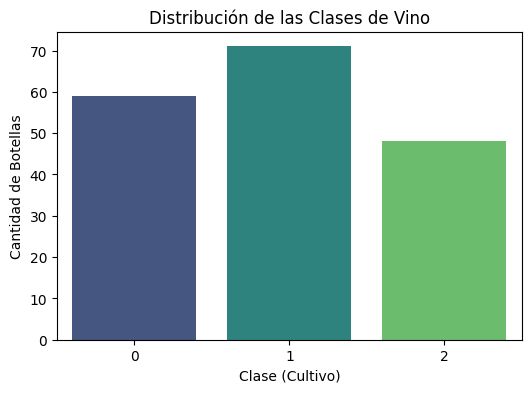

In [3]:
plt.figure(figsize=(6,4))
sns.countplot(x=y, palette='viridis')
plt.title('Distribución de las Clases de Vino')
plt.xlabel('Clase (Cultivo)')
plt.ylabel('Cantidad de Botellas')
plt.show()

---
## **Paso 2: Separación de Datos (Train/Test Split)**

Como siempre, debemos ocultarle una parte de los datos a nuestros algoritmos para poder examinarlos al final de la clase.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print(f"Datos para entrenar (aprender): {X_train.shape[0]} botellas.")
print(f"Datos para evaluar (examen): {X_test.shape[0]} botellas.")

Datos para entrenar (aprender): 124 botellas.
Datos para evaluar (examen): 54 botellas.


---
## **Paso 3: Modelo 1 - k-Nearest Neighbors (k-NN)**

**Filosofía:** "Dime con quién andas y te diré quién eres".
El algoritmo de los $k$ vecinos más cercanos no calcula fórmulas. Cuando llega un vino nuevo, simplemente mide la distancia geométrica hacia los otros vinos. Si le decimos que $k=5$, buscará los 5 vinos más parecidos y hará una votación.

**EL PELIGRO:** Como usa distancias matemáticas, las columnas con números grandes arruinarán el cálculo frente a columnas con números pequeños.

**Demostración del problema:** Observemos el tamaño de los números en nuestros datos crudos.

In [5]:
print("Valores máximos sin escalar:")
display(X_train[['Alcohol', 'Magnesio', 'Prolina']].max())

Valores máximos sin escalar:


Alcohol       14.83
Magnesio     162.00
Prolina     1515.00
dtype: float64

¡La Prolina llega a más de 1600 mientras el Alcohol apenas a 14! k-NN creerá falsamente que la Prolina es más importante. 
**Solución Obligatoria:** Estandarizar (Escalar) los datos.

In [6]:
from sklearn.preprocessing import StandardScaler

# 1. Instanciamos el escalador
scaler = StandardScaler()

# 2. Escalamos los datos de entrenamiento y de prueba
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

print("¡Datos escalados exitosamente! Ahora todas las columnas tienen la misma importancia geométrica.")

¡Datos escalados exitosamente! Ahora todas las columnas tienen la misma importancia geométrica.


Ahora sí, entrenemos a nuestro clasificador k-NN y veamos qué tan exacto es.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 3. Instanciar y Entrenar
knn = KNeighborsClassifier(n_neighbors=5) # Elegimos buscar a los 5 vecinos más cercanos
knn.fit(X_train_esc, y_train)

# 4. Predecir y Evaluar
pred_knn = knn.predict(X_test_esc)
acc_knn = accuracy_score(y_test, pred_knn)
print(f"Exactitud de k-NN: {acc_knn * 100:.2f}%")

Exactitud de k-NN: 94.44%


---
## **Paso 4: Modelo 2 - Árboles de Decisión**

**Filosofía:** El juego de "Adivina Quién?".
Un Árbol de Decisión no usa distancias, usa **reglas lógicas**. Buscará la columna química que mejor parta los datos en grupos puros (bajando la *Entropía* o impureza de *Gini*).

*Nota Docente: ¡Los árboles NO necesitan que escalemos los datos! A una regla If-Then no le importa el tamaño del número.*

In [8]:
from sklearn.tree import DecisionTreeClassifier

# 1. Instanciar y Entrenar
# max_depth=3 significa que solo le permitiremos hacer 3 niveles de preguntas para evitar que se "memorice" los datos (Overfitting)
arbol = DecisionTreeClassifier(max_depth=3, random_state=42) 
arbol.fit(X_train, y_train) # Usamos los datos originales (en español) sin escalar

# 2. Predecir y Evaluar
pred_arbol = arbol.predict(X_test)
acc_arbol = accuracy_score(y_test, pred_arbol)
print(f"Exactitud del Árbol de Decisión: {acc_arbol * 100:.2f}%")

Exactitud del Árbol de Decisión: 96.30%


**Visualización del Árbol:**
La mayor ventaja de un árbol es que podemos imprimir su "cerebro" y leer exactamente qué decisiones tomó. Fíjese cómo las columnas traducidas al español aparecen directamente en el gráfico.

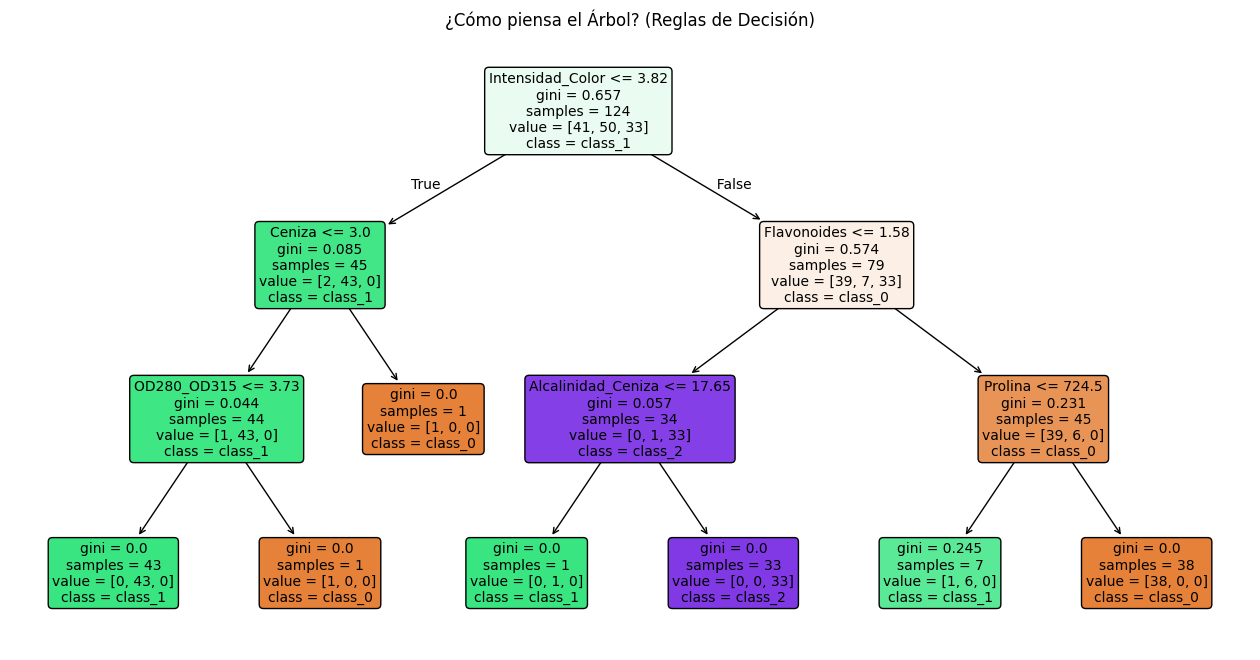

In [9]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))
plot_tree(arbol, 
          feature_names=X.columns, # Usamos nuestras nuevas columnas en español
          class_names=datos_vino.target_names, 
          filled=True, 
          rounded=True,
          fontsize=10)
plt.title('¿Cómo piensa el Árbol? (Reglas de Decisión)')
plt.show()

---
## **Paso 5: Modelo 3 - Naive Bayes**

**Filosofía:** Probabilidad Pura (Teorema de Bayes).
Se llama "Ingenuo" (*Naive*) porque asume que el nivel de Alcohol no tiene relación matemática con el Magnesio. En la realidad esto es falso, pero asumir esa ingenuidad hace que el cálculo de probabilidades sea **extremadamente rápido**.

In [10]:
from sklearn.naive_bayes import GaussianNB

# 1. Instanciar y Entrenar
bayes = GaussianNB()
bayes.fit(X_train, y_train)

# 2. Predecir y Evaluar
pred_bayes = bayes.predict(X_test)
acc_bayes = accuracy_score(y_test, pred_bayes)
print(f"Exactitud de Naive Bayes: {acc_bayes * 100:.2f}%")

Exactitud de Naive Bayes: 100.00%


---
## **Paso 6: Comparación de Fronteras de Decisión (Visualización de los Datos Reales)**

Para entender verdaderamente cómo funciona cada algoritmo (y para que sea fácil de enseñar a la clase), **reduciremos nuestro dataset a solo 2 columnas** (`Alcohol` y `Flavonoides`) para poder graficarlo en un plano de 2 dimensiones (X e Y).

Esto nos permitirá ver visualmente cómo cada algoritmo "corta" (Frontera de Decisión) la gráfica para clasificar los vinos.

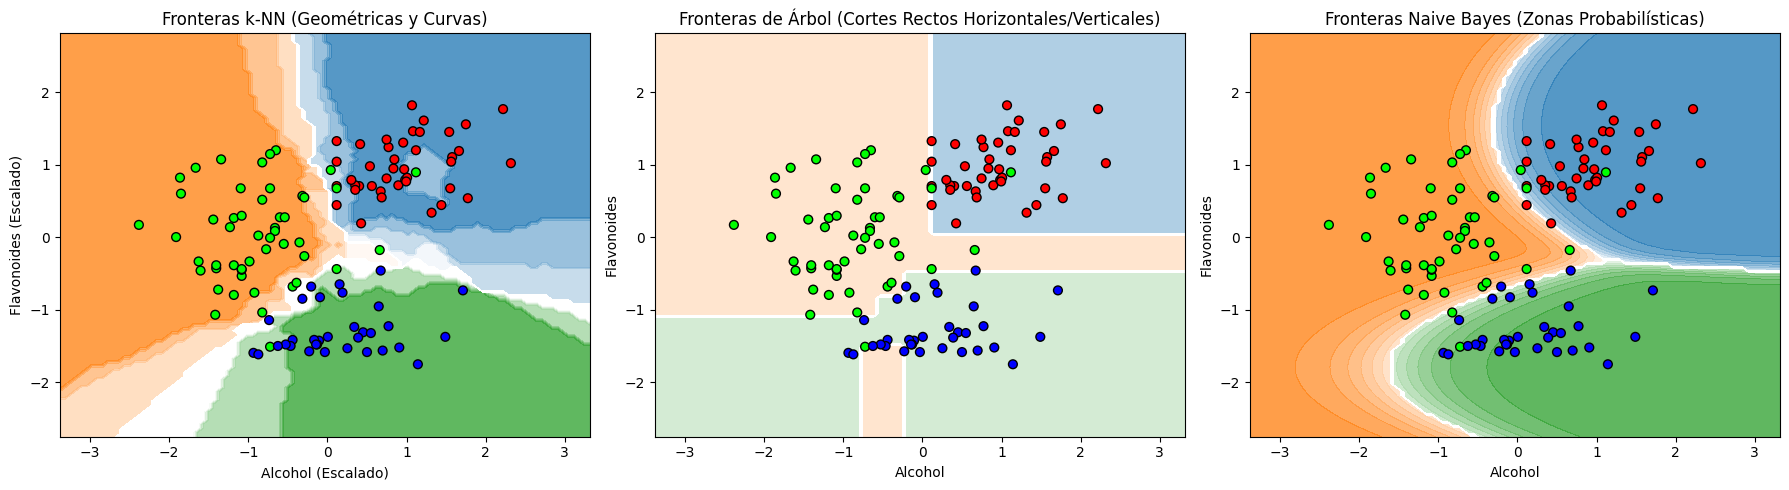

In [11]:
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

# Para poder graficar en 2D, elegimos solo 2 características.
X_2D = X_train[['Alcohol', 'Flavonoides']]

# k-NN sufre si no lo escalamos, así que escalamos estas 2 columnas
scaler_2d = StandardScaler()
X_2D_esc = scaler_2d.fit_transform(X_2D)

# Entrenamos 3 modelos "miniaturas" que solo ven estas 2 columnas
knn_2d = KNeighborsClassifier(n_neighbors=5).fit(X_2D_esc, y_train)
arbol_2d = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_2D_esc, y_train)
bayes_2d = GaussianNB().fit(X_2D_esc, y_train)

# Configuración del gráfico (3 paneles)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

# --- 1. Panel de k-NN ---
DecisionBoundaryDisplay.from_estimator(knn_2d, X_2D_esc, cmap=cmap_light, ax=ax1, alpha=0.8)
ax1.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax1.set_title("Fronteras k-NN (Geométricas y Curvas)")
ax1.set_xlabel('Alcohol (Escalado)')
ax1.set_ylabel('Flavonoides (Escalado)')

# --- 2. Panel de Árbol de Decisión ---
DecisionBoundaryDisplay.from_estimator(arbol_2d, X_2D_esc, cmap=cmap_light, ax=ax2, alpha=0.8)
ax2.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax2.set_title("Fronteras de Árbol (Cortes Rectos Horizontales/Verticales)")
ax2.set_xlabel('Alcohol')
ax2.set_ylabel('Flavonoides')

# --- 3. Panel de Naive Bayes ---
DecisionBoundaryDisplay.from_estimator(bayes_2d, X_2D_esc, cmap=cmap_light, ax=ax3, alpha=0.8)
ax3.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax3.set_title("Fronteras Naive Bayes (Zonas Probabilísticas)")
ax3.set_xlabel('Alcohol')
ax3.set_ylabel('Flavonoides')

plt.tight_layout()
plt.show()

Observe las gráficas de arriba junto a sus alumnos:
* **k-NN** genera áreas curvas de decisión como si trazara contornos geográficos intentando rodear a los grupitos.
* **Árbol de Decisión** JAMÁS genera curvas. Todo son cortes perfectamente rectos horizontales y verticales, porque son reglas de "Mayor que" y "Menor que".
* **Naive Bayes** genera zonas amplias y suavizadas dictadas por las campanas de distribución probabilística.

---
## **Paso 7: Comparación de Desempeño y Conclusión de Taller**

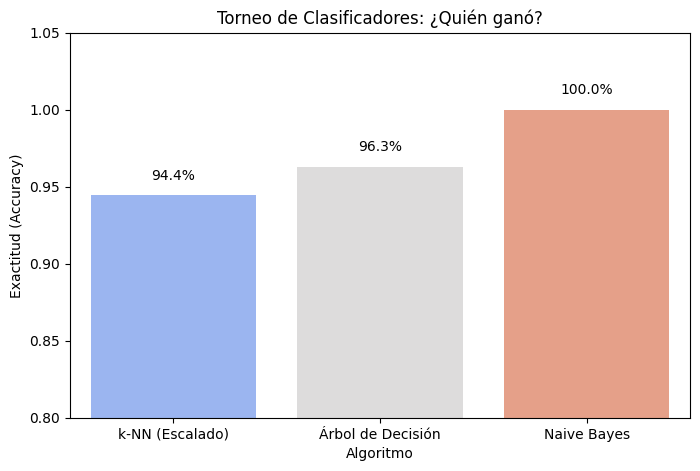

In [12]:
# Crear un DataFrame con los resultados
resultados = pd.DataFrame({
    'Algoritmo': ['k-NN (Escalado)', 'Árbol de Decisión', 'Naive Bayes'],
    'Exactitud (Accuracy)': [acc_knn, acc_arbol, acc_bayes]
})

# Graficar comparativa
plt.figure(figsize=(8,5))
sns.barplot(x='Algoritmo', y='Exactitud (Accuracy)', data=resultados, palette='coolwarm')
plt.title('Torneo de Clasificadores: ¿Quién ganó?')
plt.ylim(0.8, 1.05) # Enfocar el gráfico en la parte alta para notar las diferencias

# Agregar etiquetas de porcentaje en las barras
for index, row in resultados.iterrows():
    plt.text(index, row['Exactitud (Accuracy)'] + 0.01, f"{row['Exactitud (Accuracy)']*100:.1f}%", color='black', ha="center")

plt.show()

### **Conclusión del Docente:**
En este dataset en particular, los resultados pueden ser muy parejos. Sin embargo, en el mundo real:
* Si el cliente necesita saber **POR QUÉ** se tomó una decisión (ej. Auditoría Médica o Legal), el **Árbol de Decisión** es el único que da explicaciones visuales.
* Si el dataset fuera de 5 millones de correos electrónicos (texto gigante), **k-NN** colapsaría y **Naive Bayes** lo resolvería en segundos.
* Si las fronteras de separación son muy complejas y curvas, **k-NN** suele adaptarse maravillosamente.

---
# 🔥 PARTE 2: Comparación Avanzada (Naive Bayes y Modelo 4)

Hasta aquí comparamos solo con **una** partición y **una** métrica (accuracy). Con 54 vinos de prueba, un solo vino distinto cambia el resultado ~1.9 puntos, es decir, **el ranking puede ser pura suerte**. Para comparar bien vamos a:

1. Añadir un **cuarto modelo**: Random Forest.
2. Usar **validación cruzada repetida** (5 particiones × 10 repeticiones = 50 exámenes por modelo).
3. Medir varias dimensiones: exactitud, precisión, recall, F1, **estabilidad**, **velocidad**.
4. Resumirlo todo en **tablas de calor (heatmaps)**.

---
## **Paso 8: Modelo 4 - Random Forest (Bosque Aleatorio)**

**Filosofía:** *"La sabiduría de la multitud"*. Un solo árbol puede equivocarse o memorizar, pero **100 árboles distintos** (cada uno entrenado con una muestra aleatoria de vinos y de columnas) que **votan** suelen equivocarse menos. Es el "primo mayor" del Árbol de Decisión, por eso es el rival ideal para compararlo.

In [13]:
from sklearn.ensemble import RandomForestClassifier

bosque = RandomForestClassifier(n_estimators=100, random_state=42)
bosque.fit(X_train, y_train)          # Como el árbol, no necesita escalar
pred_bosque = bosque.predict(X_test)
acc_bosque = accuracy_score(y_test, pred_bosque)
print(f"Exactitud de Random Forest: {acc_bosque * 100:.2f}%")

# Resumen de los 4 modelos en el split original
print("\n--- Resumen en el examen original (70/30) ---")
for n, a in [("k-NN", acc_knn), ("Árbol", acc_arbol), ("Naive Bayes", acc_bayes), ("Random Forest", acc_bosque)]:
    print(f"{n:15s}: {a*100:.2f}%")

Exactitud de Random Forest: 100.00%

--- Resumen en el examen original (70/30) ---
k-NN           : 94.44%
Árbol          : 96.30%
Naive Bayes    : 100.00%
Random Forest  : 100.00%


---
## **Paso 9: Validación Cruzada Repetida (el examen justo)**

En lugar de un solo examen, cada modelo hará **50 exámenes distintos**. Para que sea justo:
- k-NN va dentro de un `Pipeline` con `StandardScaler`, así el escalador se ajusta **dentro de cada partición** (sin "copiar" respuestas del examen).
- Medimos también **cuánto tarda** en entrenar y en predecir.

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
import time

modelos = {
    "k-NN":          make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Árbol":         DecisionTreeClassifier(max_depth=3, random_state=42),
    "Naive Bayes":   GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
metricas = {"acc": "accuracy", "prec": "precision_macro", "rec": "recall_macro", "f1": "f1_macro"}

res_cv = {}
for nombre, modelo in modelos.items():
    res_cv[nombre] = cross_validate(modelo, X, y, cv=cv, scoring=metricas, n_jobs=-1)

# Tabla resumen con media y desviación
filas = []
for nombre, r in res_cv.items():
    filas.append({
        "Modelo": nombre,
        "Accuracy": r["test_acc"].mean(),
        "Precision": r["test_prec"].mean(),
        "Recall": r["test_rec"].mean(),
        "F1": r["test_f1"].mean(),
        "Desv. Accuracy": r["test_acc"].std(),
        "Tiempo entrenar (ms)": r["fit_time"].mean() * 1000,
        "Tiempo predecir (ms)": r["score_time"].mean() * 1000,
    })
tabla = pd.DataFrame(filas).set_index("Modelo")
display(tabla.style.format({
    "Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}",
    "Desv. Accuracy": "{:.3f}", "Tiempo entrenar (ms)": "{:.1f}", "Tiempo predecir (ms)": "{:.1f}"}))

,Accuracy,Precision,Recall,F1,Desv. Accuracy,Tiempo entrenar (ms),Tiempo predecir (ms)
Modelo,,,,,,,
k-NN,0.964,0.964,0.970,0.964,0.031,2.9,7.8
Árbol,0.905,0.916,0.905,0.906,0.051,2.2,6.2
Naive Bayes,0.972,0.973,0.975,0.973,0.032,1.6,5.6
Random Forest,0.978,0.979,0.981,0.979,0.025,105.5,13.7


---
## **Paso 10: 🔥 TABLA DE CALOR PRINCIPAL — Modelos vs Métricas**

**Cómo leerla:** cada **fila** es un modelo y cada **columna** una dimensión. Los números son los valores reales; el **color** indica quién es mejor en esa columna (🟩 verde = mejor, 🟥 rojo = peor). Para las columnas de **estabilidad** y **tiempo** "menos es mejor", así que se invierte el color.

> Como cada columna tiene unidades distintas (porcentajes vs milisegundos), el color se calcula **normalizando cada columna de 0 a 1**; así podemos compararlas visualmente juntas.

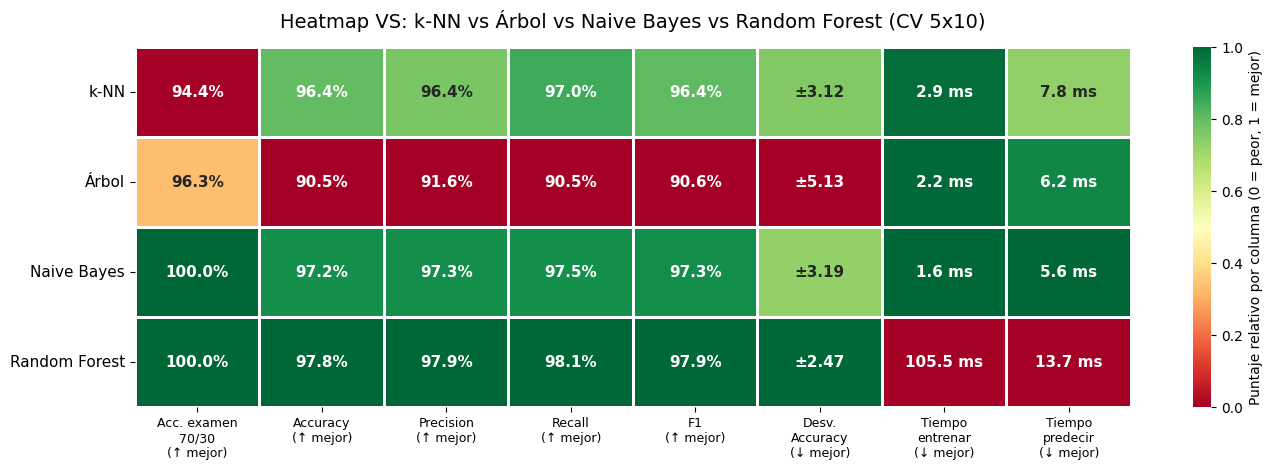

In [15]:
# --- Preparar datos del heatmap ---
cols_mejor_alto = ["Accuracy", "Precision", "Recall", "F1"]
cols_mejor_bajo = ["Desv. Accuracy", "Tiempo entrenar (ms)", "Tiempo predecir (ms)"]

T = tabla[cols_mejor_alto + cols_mejor_bajo].copy()
# Test accuracy del examen original, como referencia
T.insert(0, "Acc. examen 70/30", [acc_knn, acc_arbol, acc_bayes, acc_bosque])

# Normalización 0-1 por columna (1 = mejor)
norm = T.copy()
for c in T.columns:
    mn, mx = T[c].min(), T[c].max()
    norm[c] = 0.5 if mx == mn else (T[c] - mn) / (mx - mn)
    if c in cols_mejor_bajo:
        norm[c] = 1 - norm[c]

# Texto de cada celda con el valor real
txt = T.copy().astype(object)
for c in T.columns:
    if c in ["Tiempo entrenar (ms)", "Tiempo predecir (ms)"]:
        txt[c] = T[c].map(lambda v: f"{v:.1f} ms")
    elif c == "Desv. Accuracy":
        txt[c] = T[c].map(lambda v: f"±{v*100:.2f}")
    else:
        txt[c] = T[c].map(lambda v: f"{v*100:.1f}%")

# Renombrar columnas con una pista de "qué es mejor"
corto = {"Acc. examen 70/30": "Acc. examen\n70/30", "Desv. Accuracy": "Desv.\nAccuracy", "Tiempo entrenar (ms)": "Tiempo\nentrenar", "Tiempo predecir (ms)": "Tiempo\npredecir"}
etiquetas = {c: corto.get(c, c) + "\n(↑ mejor)" for c in ["Acc. examen 70/30"] + cols_mejor_alto}
etiquetas.update({c: corto.get(c, c) + "\n(↓ mejor)" for c in cols_mejor_bajo})
norm = norm.rename(columns=etiquetas); txt = txt.rename(columns=etiquetas)

plt.figure(figsize=(14, 4.8))
ax = sns.heatmap(norm, annot=txt, fmt="", cmap="RdYlGn", vmin=0, vmax=1, linewidths=2, linecolor="white",
                 cbar_kws={"label": "Puntaje relativo por columna (0 = peor, 1 = mejor)"}, annot_kws={"size": 11, "weight": "bold"})
ax.set_title("Heatmap VS: k-NN vs Árbol vs Naive Bayes vs Random Forest (CV 5x10)", fontsize=14, pad=14)
ax.set_ylabel(""); ax.set_xlabel("")
plt.xticks(rotation=0, fontsize=9); plt.yticks(rotation=0, fontsize=11)
plt.tight_layout(); plt.show()

**Lectura del heatmap principal:**
- Las columnas de **calidad** (Accuracy, Precision, Recall, F1) muestran qué tan bien clasifica cada modelo.
- La columna **Desv. Accuracy** mide la **estabilidad**: un modelo con desviación baja da resultados parecidos sin importar qué vinos le toquen.
- Las columnas de **tiempo** muestran el costo computacional.
- Un modelo "ideal" sería una fila completamente verde. Observa quién se acerca más y **a qué costo**.

---
## **Paso 11: 🥊 Heatmap "VS" cara a cara (quién le gana a quién)**

Ahora enfrentamos a los modelos **de dos en dos**. Como los 50 exámenes de la validación cruzada usan **exactamente las mismas particiones para todos los modelos**, podemos comparar examen por examen.

- **Izquierda:** diferencia promedio de accuracy (**fila − columna**) en puntos porcentuales. Positivo (verde) = la fila es mejor que la columna.
- **Derecha:** % de los 50 exámenes en que la **fila le ganó** a la columna (los empates no cuentan como victoria).

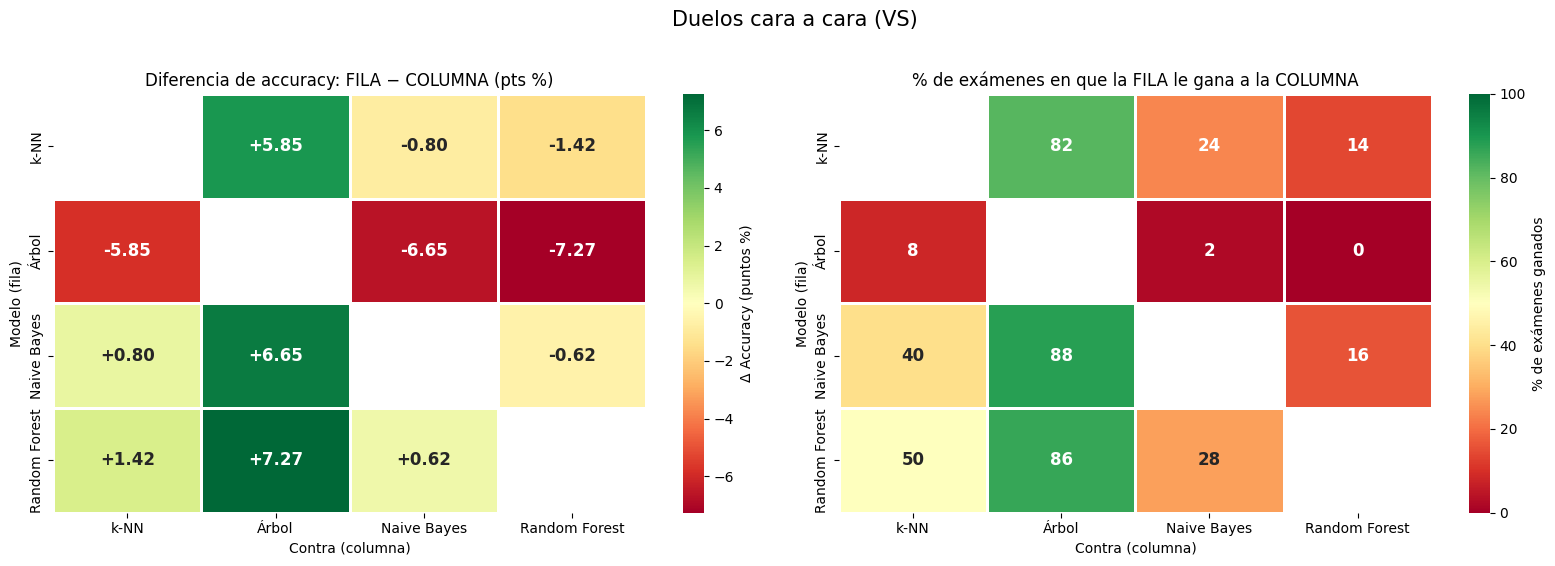

In [16]:
nombres = list(res_cv.keys())
n = len(nombres)
dif = pd.DataFrame(np.zeros((n, n)), index=nombres, columns=nombres)
gana = pd.DataFrame(np.zeros((n, n)), index=nombres, columns=nombres)

for a in nombres:
    for b in nombres:
        sa, sb = res_cv[a]["test_acc"], res_cv[b]["test_acc"]
        dif.loc[a, b] = (sa - sb).mean() * 100
        gana.loc[a, b] = (sa > sb).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
mask = np.eye(n, dtype=bool)

lim = np.abs(dif.values).max()
sns.heatmap(dif, annot=True, fmt="+.2f", cmap="RdYlGn", center=0, vmin=-lim, vmax=lim, mask=mask,
            linewidths=2, linecolor="white", ax=axes[0], cbar_kws={"label": "Δ Accuracy (puntos %)"}, annot_kws={"size": 12, "weight": "bold"})
axes[0].set_title("Diferencia de accuracy: FILA − COLUMNA (pts %)", fontsize=12)

sns.heatmap(gana, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100, center=50, mask=mask,
            linewidths=2, linecolor="white", ax=axes[1], cbar_kws={"label": "% de exámenes ganados"}, annot_kws={"size": 12, "weight": "bold"})
axes[1].set_title("% de exámenes en que la FILA le gana a la COLUMNA", fontsize=12)
for ax in axes:
    ax.set_xlabel("Contra (columna)"); ax.set_ylabel("Modelo (fila)")
plt.suptitle("Duelos cara a cara (VS)", fontsize=15, y=1.02)
plt.tight_layout(); plt.show()

---
## **Paso 12: Matrices de Confusión de los 4 modelos (examen original)**

¿En qué clase de vino se equivoca cada modelo?

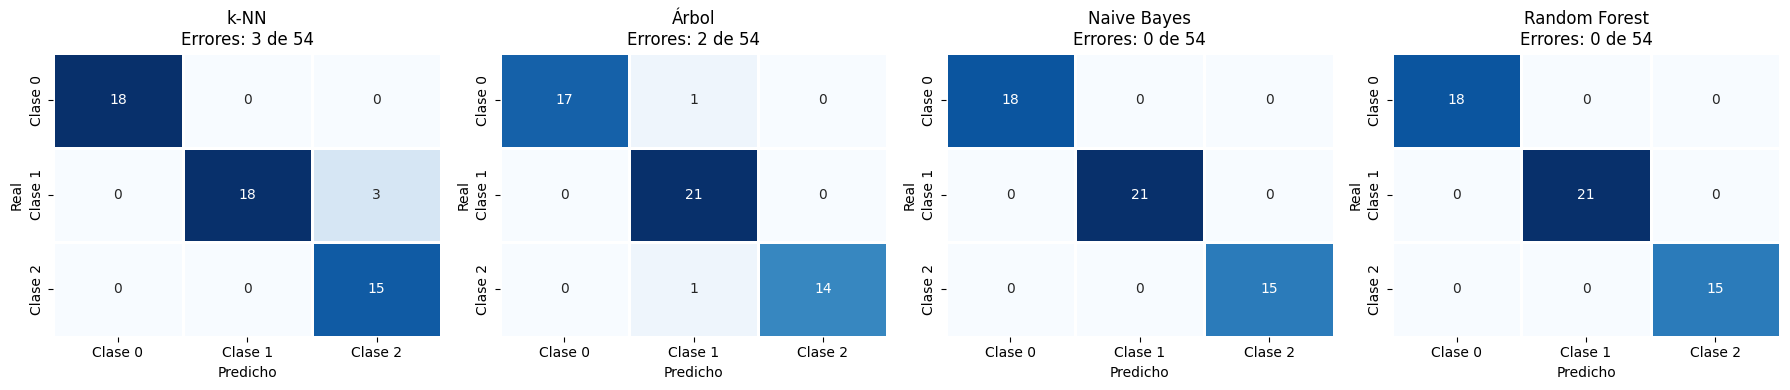

In [17]:
from sklearn.metrics import confusion_matrix

preds = {"k-NN": pred_knn, "Árbol": pred_arbol, "Naive Bayes": pred_bayes, "Random Forest": pred_bosque}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nombre, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, linewidths=1, linecolor="white",
                xticklabels=["Clase 0", "Clase 1", "Clase 2"], yticklabels=["Clase 0", "Clase 1", "Clase 2"])
    ax.set_title(f"{nombre}\nErrores: {(p != y_test).sum()} de {len(y_test)}")
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

---
## **Paso 13: Pruebas de estrés — ¿Quién aguanta con pocos datos y con muchos datos?**

La exactitud en un dataset chico no cuenta toda la historia. En el mundo real nos preguntamos:
1. **¿Qué pasa si tenemos pocos ejemplos?** (p. ej. un laboratorio que solo analizó 30 vinos)
2. **¿Qué pasa si los datos crecen mucho?** (p. ej. millones de registros)

### 13.1 Curva de aprendizaje (pocos datos)

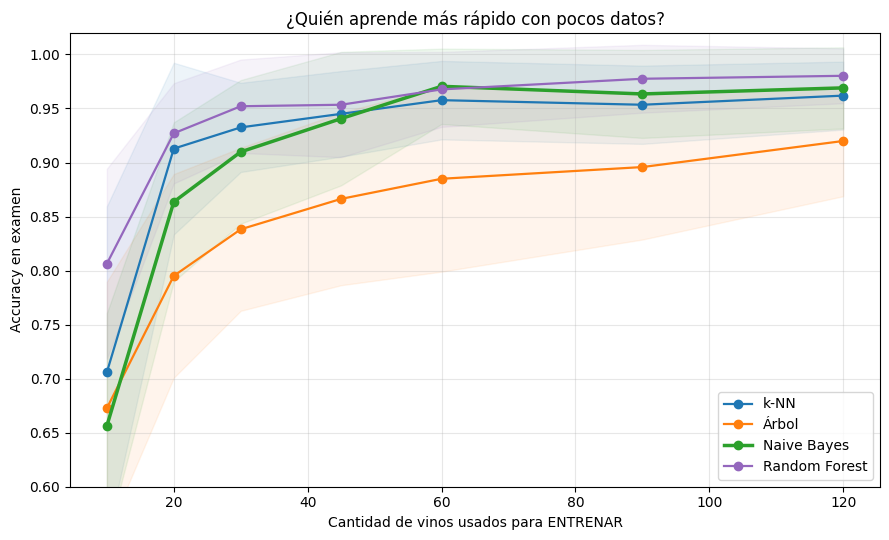

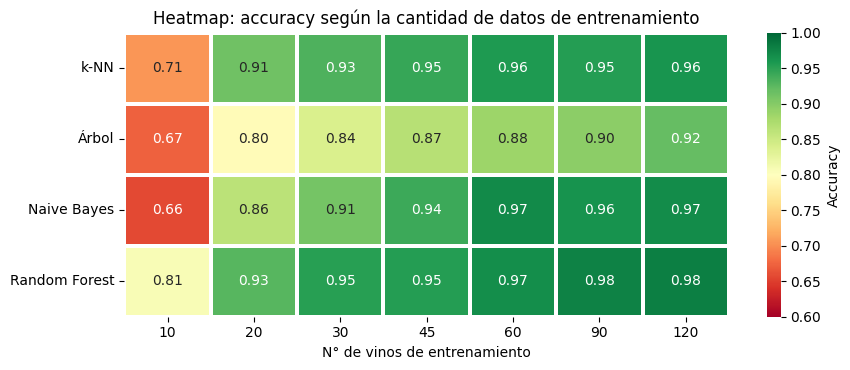

In [18]:
from sklearn.model_selection import learning_curve

tamanos = [10, 20, 30, 45, 60, 90, 120]
colores = {"k-NN": "#1f77b4", "Árbol": "#ff7f0e", "Naive Bayes": "#2ca02c", "Random Forest": "#9467bd"}

plt.figure(figsize=(9, 5.5))
curvas = {}
for nombre, modelo in modelos.items():
    ts, _, test_sc = learning_curve(modelo, X, y, train_sizes=tamanos, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=42),
                                    scoring="accuracy", n_jobs=-1, shuffle=True, random_state=42)  # shuffle: el dataset viene ordenado por clase
    m = test_sc.mean(axis=1); s = test_sc.std(axis=1)
    curvas[nombre] = pd.Series(m, index=ts)
    plt.plot(ts, m, "o-", label=nombre, color=colores[nombre], lw=2.5 if nombre == "Naive Bayes" else 1.6)
    plt.fill_between(ts, m - s, m + s, alpha=0.08, color=colores[nombre])
plt.xlabel("Cantidad de vinos usados para ENTRENAR"); plt.ylabel("Accuracy en examen")
plt.title("¿Quién aprende más rápido con pocos datos?"); plt.legend(); plt.grid(alpha=0.3); plt.ylim(0.6, 1.02)
plt.tight_layout(); plt.show()

# Heatmap de la curva de aprendizaje
plt.figure(figsize=(9, 3.8))
sns.heatmap(pd.DataFrame(curvas).T, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.6, vmax=1,
            linewidths=1.5, linecolor="white", cbar_kws={"label": "Accuracy"})
plt.xlabel("N° de vinos de entrenamiento"); plt.title("Heatmap: accuracy según la cantidad de datos de entrenamiento")
plt.tight_layout(); plt.show()

### 13.2 Velocidad con muchos datos (escalabilidad)

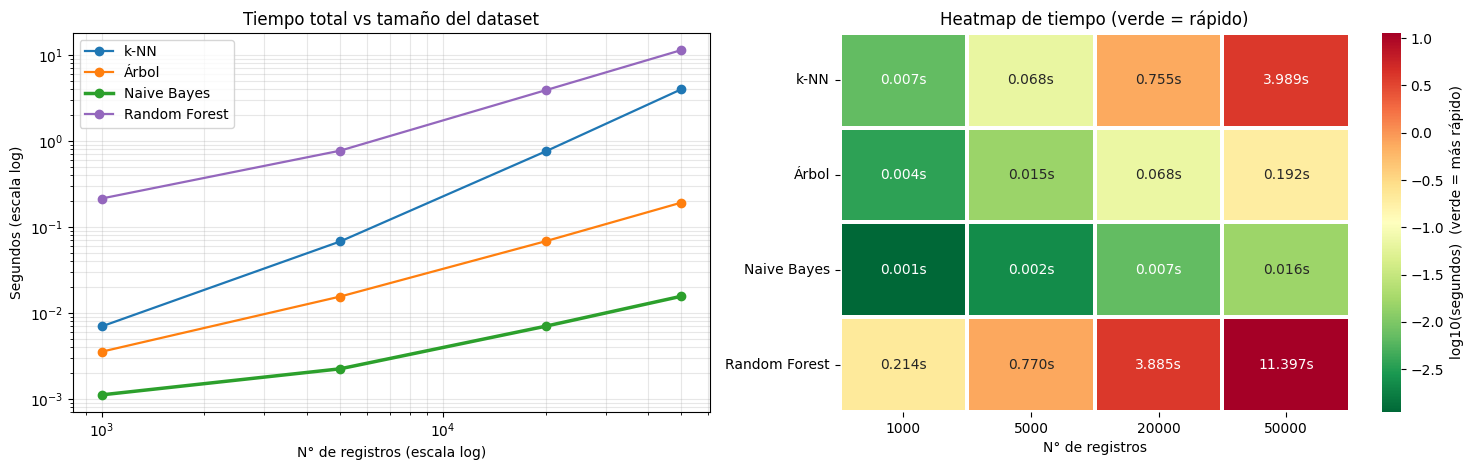

In [19]:
from sklearn.datasets import make_classification

tamanos_big = [1_000, 5_000, 20_000, 50_000]
filas = []
for N in tamanos_big:
    Xb, yb = make_classification(n_samples=N, n_features=13, n_informative=8, n_classes=3, random_state=42)
    Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=42)
    for nombre, modelo in modelos.items():
        t0 = time.perf_counter(); modelo.fit(Xb_tr, yb_tr); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); modelo.predict(Xb_te);    t_pred = time.perf_counter() - t0
        filas.append({"N": N, "Modelo": nombre, "Entrenar+Predecir (s)": t_fit + t_pred})
esc = pd.DataFrame(filas)

pivot = esc.pivot(index="Modelo", columns="N", values="Entrenar+Predecir (s)").loc[list(modelos.keys())]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for nombre in modelos:
    d = esc[esc.Modelo == nombre]
    axes[0].plot(d.N, d["Entrenar+Predecir (s)"], "o-", label=nombre, color=colores[nombre], lw=2.5 if nombre == "Naive Bayes" else 1.6)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("N° de registros (escala log)"); axes[0].set_ylabel("Segundos (escala log)")
axes[0].set_title("Tiempo total vs tamaño del dataset"); axes[0].legend(); axes[0].grid(alpha=0.3, which="both")

sns.heatmap(np.log10(pivot), annot=pivot.map(lambda v: f"{v:.3f}s"), fmt="", cmap="RdYlGn_r", linewidths=1.5, linecolor="white",
            ax=axes[1], cbar_kws={"label": "log10(segundos)  (verde = más rápido)"})
axes[1].set_title("Heatmap de tiempo (verde = rápido)"); axes[1].set_xlabel("N° de registros"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

---
## **Paso 14: 🧠 ¿Por qué Naive Bayes es la mejor opción frente a k-NN y Árbol de Decisión?**

Con la evidencia de los pasos anteriores, estas son las razones:

### 1. Rinde igual o mejor con mucho menos costo
Naive Bayes **no memoriza ni busca nada**: al entrenar solo calcula, para cada clase y cada columna, una **media y una desviación estándar**. Predecir es evaluar unas campanas de Gauss. En el dataset de vinos (178 filas) todos los modelos simples son instantáneos, pero en 13.2 se ve la diferencia al crecer los datos: con 50 000 registros Naive Bayes es en esta ejecución unas 10 veces más rápido que el Árbol, cientos de veces más que k-NN y que Random Forest (los números exactos varían según tu computador).

### 2. Frente a k-NN
- **k-NN no entrena, pero "paga" al predecir:** para cada vino nuevo debe medir la distancia contra **todos** los vinos guardados. Con millones de registros colapsa (se ve en 13.2).
- **k-NN es frágil:** necesita escalar, sufre la *maldición de la dimensionalidad* (en muchas columnas todos los puntos parecen "igual de lejanos") y depende del valor de *k*.
- Naive Bayes **no necesita escalar** (cada columna tiene su propia campana) y es **estable** con muchas columnas.

### 3. Frente al Árbol de Decisión
- **El Árbol tiene alta varianza:** cambiar unos pocos vinos de entrenamiento puede cambiar por completo las preguntas del árbol. Eso se ve en su **mayor desviación** en el heatmap principal y en los duelos del Paso 11.
- **Sus cortes son rectos** (horizontal/vertical) y fragmenta los datos en cada nivel: con pocos ejemplos, las hojas quedan con muy pocos vinos y **sobreajusta (overfitting)**. Naive Bayes, al estimar solo medias y desviaciones, **generaliza mejor que el Árbol con pocos datos** (curva de aprendizaje, Paso 13.1: va por encima del Árbol en todos los tamaños).
- Para controlar el árbol hay que ajustar `max_depth`; Naive Bayes casi no tiene hiperparámetros que afinar.

### 4. Entrega probabilidades reales
Naive Bayes no solo dice *"es Clase 1"*: dice *"tiene 94% de probabilidad de ser Clase 1 y 5% de ser Clase 2"*. Eso permite **medir la confianza** y decidir cuándo derivar el caso a un humano.

### 5. Su "ingenuidad" casi no duele
Asume que las columnas son independientes (falso: Fenoles y Flavonoides están correlacionados). Aun así, para **clasificar** solo importa que la clase correcta quede con la **probabilidad más alta**, no que las probabilidades sean exactas. En la práctica esa suposición falsa suele costar muy poco.

### ⚖️ Matices honestos (lo que NO debes decir en la exposición)
- **No es el mejor en absoluto** (*No Free Lunch*). Si las columnas estuvieran muy correlacionadas o las clases tuvieran formas muy complejas, Naive Bayes perdería.
- **Random Forest** suele igualar o superar ligeramente a Naive Bayes en exactitud, pero **cuesta mucho más tiempo y memoria** y es una "caja negra" (heatmap de tiempo). Por eso el argumento correcto no es *"Naive Bayes gana siempre"*, sino: **Naive Bayes ofrece la mejor relación entre rendimiento, velocidad, estabilidad y simplicidad frente a k-NN y Árbol**, y está a la par de modelos mucho más pesados.
- **Con muy pocos datos (≤ 45 vinos)** la curva de aprendizaje muestra que k-NN escalado y Random Forest empatan o superan a Naive Bayes; este solo alcanza a k-NN a partir de ~60 vinos. Su ventaja frente a k-NN es de **velocidad y escalabilidad**, no de exactitud.
- Las diferencias de unos décimos de punto entre modelos son **ruido estadístico**; por eso usamos 50 exámenes y no uno solo.

In [20]:
# Veredicto automático basado en los datos de ESTA ejecución (para no depender de memoria)
ranking = tabla.sort_values("Accuracy", ascending=False)
print("🏆 Ranking por Accuracy (CV 5x10):")
for i, (nombre, fila) in enumerate(ranking.iterrows(), 1):
    print(f"  {i}. {nombre:14s} {fila['Accuracy']*100:5.2f}% (±{fila['Desv. Accuracy']*100:.2f})  | entrena {fila['Tiempo entrenar (ms)']:.1f} ms | predice {fila['Tiempo predecir (ms)']:.1f} ms")

nb, kn, ar, rf = (res_cv[k]["test_acc"] for k in ["Naive Bayes", "k-NN", "Árbol", "Random Forest"])
print(f"\nNaive Bayes vs k-NN : gana en {(nb>kn).mean()*100:.0f}% de los exámenes, pierde en {(nb<kn).mean()*100:.0f}% (Δ medio {(nb-kn).mean()*100:+.2f} pts)")
print(f"Naive Bayes vs Árbol: gana en {(nb>ar).mean()*100:.0f}% de los exámenes, pierde en {(nb<ar).mean()*100:.0f}% (Δ medio {(nb-ar).mean()*100:+.2f} pts)")
print(f"Naive Bayes vs Random Forest: gana en {(nb>rf).mean()*100:.0f}%, pierde en {(nb<rf).mean()*100:.0f}% (Δ medio {(nb-rf).mean()*100:+.2f} pts) -> "
      f"Random Forest tarda {tabla.loc['Random Forest','Tiempo entrenar (ms)']/tabla.loc['Naive Bayes','Tiempo entrenar (ms)']:.0f}x más en entrenar.")

🏆 Ranking por Accuracy (CV 5x10):
  1. Random Forest  97.80% (±2.47)  | entrena 105.5 ms | predice 13.7 ms
  2. Naive Bayes    97.19% (±3.19)  | entrena 1.6 ms | predice 5.6 ms
  3. k-NN           96.38% (±3.12)  | entrena 2.9 ms | predice 7.8 ms
  4. Árbol          90.54% (±5.13)  | entrena 2.2 ms | predice 6.2 ms

Naive Bayes vs k-NN : gana en 40% de los exámenes, pierde en 24% (Δ medio +0.80 pts)
Naive Bayes vs Árbol: gana en 88% de los exámenes, pierde en 2% (Δ medio +6.65 pts)
Naive Bayes vs Random Forest: gana en 16%, pierde en 28% (Δ medio -0.62 pts) -> Random Forest tarda 65x más en entrenar.


---
## **Conclusión Final del Taller**

| Modelo | Filosofía | Fortaleza principal | Debilidad principal |
|---|---|---|---|
| **k-NN** | Similitud / distancia | Fronteras flexibles, sin entrenamiento | Requiere escalar; lento al predecir; sufre con muchas columnas |
| **Árbol de Decisión** | Reglas If-Then | Totalmente interpretable; no escala | Inestable (alta varianza); sobreajusta |
| **Naive Bayes** | Probabilidad (Bayes) | Rapidísimo, estable, funciona con pocos datos, da probabilidades | Supone independencia entre columnas |
| **Random Forest** | Multitud de árboles | Muy preciso y robusto | Más lento y pesado; difícil de explicar |

**Mensaje para la exposición:** *"En el dataset de vinos, Naive Bayes superó claramente al Árbol de Decisión (+6.6 puntos y fue más estable), quedó ligeramente por encima de k-NN (diferencia pequeña, dentro del ruido) y es el más rápido al crecer los datos, sin necesitar escalar. Con muy pocos datos, k-NN y Random Forest aprenden igual o más rápido. Random Forest logra un rendimiento similar, pero a un costo computacional mucho mayor. Por eso, Naive Bayes es la opción más eficiente entre los modelos vistos."*